# 2. OCR from bubble crops

Load bubbles.json, run PaddleOCR 3 on each crop, and save text plus line confidences. Set LANGUAGE to match the page. OCR ordering follows PaddleOCR within each bubble.

Run cells top to bottom, then inspect the displayed output before continuing.

Use the **.venvOCR (1pageTest OCR)** kernel. It points to the existing Python 3.11 environment at `C:/Users/ESHAAN/BYTE/Applied-Task/MultiModelSystem/.venvOCR`, with PaddleOCR and PaddlePaddle GPU already installed.


In [1]:
import sys
print(sys.executable)

c:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\.venvOCR\Scripts\python.exe


In [2]:
from pathlib import Path
import hashlib
import json
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# Works when the kernel starts in the project root or this stage folder.
ROOT = Path.cwd().resolve()
if not (ROOT / "models.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "models.json").exists():
    raise FileNotFoundError("Start the kernel in 1pageTest or a stage folder.")
SEQUENCE_ID = "seq_71033fec4de494fc"
PAGE_NUMBER = 1
# Dataset page filenames are zero-padded: page 1 is 01.png.
PAGE = ROOT / "TaskData/development/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
OUT = ROOT / "data/intermediate"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = json.loads((ROOT / "models.json").read_text(encoding="utf-8"))
if not PAGE.is_file():
    raise FileNotFoundError(f"Put your manga page at {PAGE}, or edit PAGE.")
page = Image.open(PAGE).convert("RGB")
PAGE_INFO = {"name": PAGE.name, "sha256": hashlib.sha256(PAGE.read_bytes()).hexdigest(),
             "width": page.width, "height": page.height}

def save_stage(name, records):
    path = OUT / name
    path.write_text(json.dumps({"page": PAGE_INFO, "records": records},
                               ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved {path}")

def load_stage(name):
    path = OUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run the preceding stage first.")
    payload = json.loads(path.read_text(encoding="utf-8"))
    if payload["page"] != PAGE_INFO:
        raise ValueError(f"{name} belongs to a different page. Rerun the earlier stages.")
    return payload["records"]


In [3]:
import numpy as np
from paddleocr import PaddleOCR

bubbles = load_stage("bubbles.json")
LANGUAGE = "en"  # For Japanese pages use "japan".
ocr = PaddleOCR(lang=LANGUAGE, use_doc_orientation_classify=False,
                use_doc_unwarping=False, use_textline_orientation=False)
CROPS = OUT / "bubble_crops"
CROPS.mkdir(exist_ok=True)


c:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\.venvOCR\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\.venvOCR\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\ESHAAN\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the director

Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\ocr.json
B1: 7 WOAHH!! ...THE SNAKE!!?


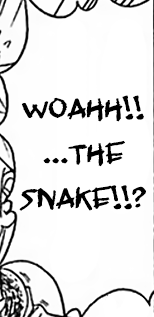

B2: TAKE IT OFF! TAKE IT OFF!! 口


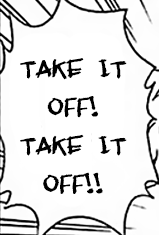

B3: THIS I5 BAD! IT'S GOING TO BITE ME! O


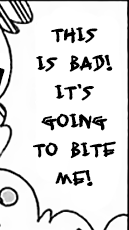

B4: NANKURU- NAISA.


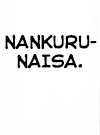

B5: NANKURU- NAISA.


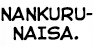

B6: HAHA, YOU SURE SCARE EASY KID~ BUT THAT'S


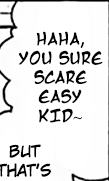

B7: REAL VIPERS ARE ACTLUALLY VERY DAN- GEROUS.


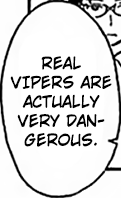

B8: VT KID BUT THAT'S A GOOD THING.


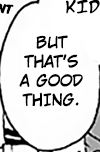

B9: IF YOU SEE A VIPER OUTSIDE, YOU SHOULD GET OUT OF THERE RIGHT AWAY!


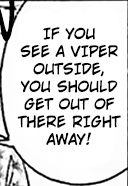

B10: A BITE TO THE FEET WILL PUT YOU TO SLEEP, AND THEN YOU MIGHT NEVER SNAKE UP AGAIN!


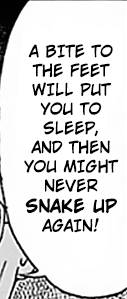

B11: ...GET IT?


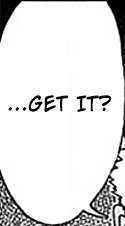

B12: IF YOU GET BITTEN, YOU MIGHT END UP LOSING YOUR LIFE.


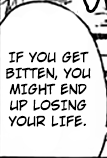

B13: DO YOU KNOW WHERE SNAKES TEND TO BITE THE MOST?


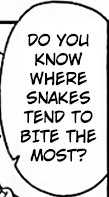

B14: UH...? THE LEGS?


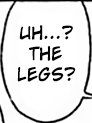

B15: YES! THEY GO FOR THE FEET!


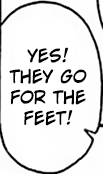

In [4]:
ocr_results = []
for bubble in bubbles:
    crop = page.crop(bubble["box"])
    crop.save(CROPS / f"{bubble['bubble_id']}.png")
    lines = []
    for result in ocr.predict(input=np.asarray(crop)):
        for text, score in zip(result["rec_texts"], result["rec_scores"]):
            lines.append({"text": str(text), "confidence": float(score)})
    ocr_results.append({"bubble_id": bubble["bubble_id"], "box": bubble["box"],
                        "text": " ".join(line["text"] for line in lines), "lines": lines})
save_stage("ocr.json", ocr_results)
for record in ocr_results:
    print(f"{record['bubble_id']}: {record['text'] or '[no text recognized]'}")
    display(Image.open(CROPS / f"{record['bubble_id']}.png"))


## Clean duplicate bubbles

Keep the larger box when two boxes overlap by at least 80% of the smaller box and have the same OCR text (ignoring case and whitespace). Equal text in separate bubbles stays. Raw files are preserved.


In [5]:
# Remove only overlapping bubbles with the same non-empty OCR text.
def normalize_text(text):
    return " ".join(text.upper().split())

def box_area(box):
    x1, y1, x2, y2 = box
    return max(0, x2 - x1) * max(0, y2 - y1)

ocr_by_id = {record["bubble_id"]: record for record in ocr_results}
kept_bubbles = []
removed_ids = []
MIN_OVERLAP = 0.80

# Check larger boxes first so a duplicate inner box is removed.
for bubble in sorted(bubbles, key=lambda b: box_area(b["box"]), reverse=True):
    text = normalize_text(ocr_by_id[bubble["bubble_id"]]["text"])
    duplicate = False
    for kept in kept_bubbles:
        kept_text = normalize_text(ocr_by_id[kept["bubble_id"]]["text"])
        if not text or text != kept_text:
            continue
        x1, y1, x2, y2 = bubble["box"]
        kx1, ky1, kx2, ky2 = kept["box"]
        intersection = max(0, min(x2, kx2) - max(x1, kx1)) * max(0, min(y2, ky2) - max(y1, ky1))
        smaller_area = min(box_area(bubble["box"]), box_area(kept["box"]))
        if smaller_area > 0 and intersection / smaller_area >= MIN_OVERLAP:
            duplicate = True
            print(f"Remove {bubble['bubble_id']}: duplicate of {kept['bubble_id']}")
            break
    if duplicate:
        removed_ids.append(bubble["bubble_id"])
    else:
        kept_bubbles.append(bubble)

# Keep the original order and IDs. Keep unmatched and empty OCR bubbles too.
clean_bubbles = [b for b in bubbles if b["bubble_id"] not in removed_ids]
clean_ocr = [r for r in ocr_results if r["bubble_id"] not in removed_ids]
save_stage("bubbles_clean.json", clean_bubbles)
save_stage("ocr_clean.json", clean_ocr)
print(f"Kept {len(clean_bubbles)} bubbles; removed {len(removed_ids)} duplicates.")


Remove B5: duplicate of B4
Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\bubbles_clean.json
Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\ocr_clean.json
Kept 14 bubbles; removed 1 duplicates.


## Match each retained bubble to one GT speaker

Read this sequence and page from `TaskData/development/labels.jsonl`. Choose one highest-scoring transcript match, accepting scores of at least 80. Exact matches score 100. A tie uses the first GT entry. No multiple-match or split-transcript handling for now. Unmatched bubbles remain with `speaker=None`; this does not mean `UNKNOWN`. These GT labels are saved separately and are not passed into the inference prompt.


In [6]:
from difflib import SequenceMatcher

LABELS = ROOT / "TaskData/development/labels.jsonl"
sequence = None
with LABELS.open(encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue
        entry = json.loads(line)
        if entry["sequence_id"] == SEQUENCE_ID:
            sequence = entry
            break
if sequence is None:
    raise ValueError(f"No GT for sequence {SEQUENCE_ID}")
gt_dialogue = sequence["pages"][PAGE_NUMBER - 1]
if not gt_dialogue:
    raise ValueError("This page has no GT dialogue.")

MIN_MATCH_SCORE = 80.0  # Raise this for stricter matches.
bubble_gt_labels = []
for record in clean_ocr:
    text = normalize_text(record["text"])
    best_gt = None
    best_score = -1.0
    for gt in gt_dialogue:
        score = 100 * SequenceMatcher(None, text, normalize_text(gt["text"])).ratio() if text else 0.0
        if score > best_score:
            best_gt = gt
            best_score = score
    speaker = best_gt["speaker"] if text and best_score >= MIN_MATCH_SCORE else None
    label = {
        "bubble_id": record["bubble_id"],
        "text": record["text"],
        "gt_text": best_gt["text"] if speaker is not None else None,
        "speaker": speaker,
        "match_score": round(best_score, 1),
    }
    bubble_gt_labels.append(label)
    print(f"{label['bubble_id']} -> {speaker} ({label['match_score']}): {record['text']}")

# No bubble is excluded because its GT match is weak or missing.
# GT speaker names are identities, not the detector's C appearance IDs.
save_stage("bubble_gt_labels.json", {
    "sequence_id": SEQUENCE_ID,
    "page_number": PAGE_NUMBER,
    "bubbles": bubble_gt_labels,
})


B1 -> character1 (95.8): 7 WOAHH!! ...THE SNAKE!!?
B2 -> character1 (96.3): TAKE IT OFF! TAKE IT OFF!! 口
B3 -> character1 (94.4): THIS I5 BAD! IT'S GOING TO BITE ME! O
B4 -> character2 (96.6): NANKURU- NAISA.
B6 -> character3 (85.4): HAHA, YOU SURE SCARE EASY KID~ BUT THAT'S
B7 -> character3 (96.4): REAL VIPERS ARE ACTLUALLY VERY DAN- GEROUS.
B8 -> None (67.4): VT KID BUT THAT'S A GOOD THING.
B9 -> character3 (100.0): IF YOU SEE A VIPER OUTSIDE, YOU SHOULD GET OUT OF THERE RIGHT AWAY!
B10 -> character3 (100.0): A BITE TO THE FEET WILL PUT YOU TO SLEEP, AND THEN YOU MIGHT NEVER SNAKE UP AGAIN!
B11 -> character3 (100.0): ...GET IT?
B12 -> character3 (100.0): IF YOU GET BITTEN, YOU MIGHT END UP LOSING YOUR LIFE.
B13 -> character3 (100.0): DO YOU KNOW WHERE SNAKES TEND TO BITE THE MOST?
B14 -> character1 (100.0): UH...? THE LEGS?
B15 -> character3 (100.0): YES! THEY GO FOR THE FEET!
Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\bubble_gt_labels.json
